## Import Libraries 
Only libraries useful for this project: Matplolib, Pandas, Plotly


In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from category_encoders import OneHotEncoder
from sklearn.impute import SimpleImputer

# 1. Prepare Data

## 1.1 Import Data

Read the CSV file containing the real estate data from Mexico city. 

In [2]:
df1 = pd.read_csv("data/mexico-city-real-estate-1.csv")
df1.head()

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",5500000.0,MXN,5450245.50,289775.66,NaN,54.0,NaN,101851.851852,NaN,NaN,NaN,http://miguel-hidalgo-df.properati.com.mx/o3zb...
1,sell,house,|Iztapalapa|Distrito Federal|México|,"19.31033,-99.068557",1512000.0,MXN,1498321.97,79661.96,NaN,80.0,NaN,18900.000000,NaN,NaN,NaN,http://iztapalapa.properati.com.mx/q7t0_venta_...
2,sell,apartment,|Tlalpan|Distrito Federal|México|,"19.279771,-99.234597",926667.0,MXN,918284.00,48822.82,NaN,100.0,NaN,9266.670000,NaN,NaN,NaN,http://tlalpan.properati.com.mx/qbi4_venta_dep...
3,sell,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",6410000.0,MXN,6352013.39,337720.36,NaN,135.0,NaN,47481.481481,NaN,NaN,NaN,http://miguel-hidalgo-df.properati.com.mx/opeq...
4,sell,apartment,|Benito Juárez|Quintana Roo|México|,"21.1902642,-86.8198375",875000.0,USD,16457437.50,875000.00,0.0,263.0,NaN,3326.996198,NaN,NaN,NaN,http://cancun.properati.com.mx/hg4t_venta_depa...


In [3]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 4628 entries, 0 to 4627
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   operation                   4628 non-null   str    
 1   property_type               4628 non-null   str    
 2   place_with_parent_names     4628 non-null   str    
 3   lat-lon                     4144 non-null   str    
 4   price                       4538 non-null   float64
 5   currency                    4538 non-null   str    
 6   price_aprox_local_currency  4538 non-null   float64
 7   price_aprox_usd             4538 non-null   float64
 8   surface_total_in_m2         1668 non-null   float64
 9   surface_covered_in_m2       4436 non-null   float64
 10  price_usd_per_m2            1150 non-null   float64
 11  price_per_m2                4249 non-null   float64
 12  floor                       291 non-null    float64
 13  rooms                       136 non-null    

## 1.2 Data Cleaning 


### Drop NaN values from the dataframe `df1`



In [4]:
# show sum of NaN values in each column
df1.isnull().sum()

operation                        0
property_type                    0
place_with_parent_names          0
lat-lon                        484
price                           90
currency                        90
price_aprox_local_currency      90
price_aprox_usd                 90
surface_total_in_m2           2960
surface_covered_in_m2          192
price_usd_per_m2              3478
price_per_m2                   379
floor                         4337
rooms                         4492
expenses                      4623
properati_url                    0
dtype: int64

In [5]:
# find percentage of null values in each column
df1.isnull().mean() * 100

operation                      0.000000
property_type                  0.000000
place_with_parent_names        0.000000
lat-lon                       10.458081
price                          1.944685
currency                       1.944685
price_aprox_local_currency     1.944685
price_aprox_usd                1.944685
surface_total_in_m2           63.958513
surface_covered_in_m2          4.148660
price_usd_per_m2              75.151253
price_per_m2                   8.189283
floor                         93.712187
rooms                         97.061366
expenses                      99.891962
properati_url                  0.000000
dtype: float64

- We do not drop every row or column that contains any null value because this would remove several valuable apartment price predictors, especially location (lat-lon) and usable area (surface_covered_in_m2). Instead, we drop columns with more than 50% null values and columns that create target leakage, we then treat the remaining missing values deliberately.
- In this case, a sensible first pass is to drop:
    - `expenses` — 99.9% missing 
    - `rooms` — 97.1% missing 
    - `floor` — 93.7% missing 
    - `price_usd_per_m2` - 75% missing
    - `surface_total_in_m2` - 64% missing
    - `price_usd_per_m2` and `price_per_m2`— these are calculated from price and area, so they leak information about the target price into the model.
        - A *feature is leakage* if it contains information that would not be available independently at the time you want to predict a listing’s price. Including leakage variables can make validation metrics look unrealistically strong while hurting real-world generalization
    - `price_aprox_usd`, `price_aprox_local_currency`, and possibly `currency` — if price is the target, these are alternate representations or direct transformations of the target, so they should not be predictors - i.e. we have to choose one price target to focus on and remove the rest:
        - all price columns () have same NaN value percentage at 1.944685, therefore they are similar. Since we will be dealing with USD, we'll keep `price_aprox_usd`
    - `properati_url` — this is just a listing identifier/URL, i.e not a stable property characteristic. Same with `operation`
- We keep `lat-lon` and `surface_covered_in_m2`; both contain important signals for apartment price prediction since geographic location and size of apartment are good predictors of apartment prices. Also, their NaN value percentages are low enough to be acceptable since we can later drop them without affecting the predicting power of the source data.

In [6]:
# drop nan columns and leakage columns

columns_to_drop = [
    'expenses',
    'rooms',
    'floor',
    'price_usd_per_m2',
    'price_per_m2',
    'price_aprox_local_currency',
    'price',
    'currency',
    'surface_total_in_m2',
    'properati_url',
    'operation' 
]

# Drop these columns completely
df1 = df1.drop(columns=columns_to_drop)

df1.head()

,property_type,place_with_parent_names,lat-lon,price_aprox_usd,surface_covered_in_m2
0,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",289775.66,54.0
1,house,|Iztapalapa|Distrito Federal|México|,"19.31033,-99.068557",79661.96,80.0
2,apartment,|Tlalpan|Distrito Federal|México|,"19.279771,-99.234597",48822.82,100.0
3,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",337720.36,135.0
4,apartment,|Benito Juárez|Quintana Roo|México|,"21.1902642,-86.8198375",875000.00,263.0


In [7]:
# investigate the number of remaining NaN values
df1.isnull().sum()

property_type                0
place_with_parent_names      0
lat-lon                    484
price_aprox_usd             90
surface_covered_in_m2      192
dtype: int64

### Filter Apartment Type only

- Since we don't want to arbitrarily remove NaN values, we can further clean the data by focussing on the data we want and then we can later come back to remove any NaN values.
    - We start with focusing on the `property_tupe = apartment` since that is the type of property we will be predicting prices for

In [8]:
mask_aprt_type = df1["property_type"] =="apartment"
df1 = df1[mask_aprt_type]


In [9]:
df1.head()

,property_type,place_with_parent_names,lat-lon,price_aprox_usd,surface_covered_in_m2
0,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",289775.66,54.0
2,apartment,|Tlalpan|Distrito Federal|México|,"19.279771,-99.234597",48822.82,100.0
3,apartment,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",337720.36,135.0
4,apartment,|Benito Juárez|Quintana Roo|México|,"21.1902642,-86.8198375",875000.00,263.0
5,apartment,|Miguel Hidalgo|Distrito Federal|México|,"19.432657,-99.177444",232663.51,87.0


In [10]:
# Double check there is only one property type = apartment. Then drop the property_type column
df1["property_type"].value_counts()


property_type
apartment    3123
Name: count, dtype: int64

In [11]:
#drop the property_type column
df1.drop(columns=["property_type"], inplace = True)

df1.head()

,place_with_parent_names,lat-lon,price_aprox_usd,surface_covered_in_m2
0,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",289775.66,54.0
2,|Tlalpan|Distrito Federal|México|,"19.279771,-99.234597",48822.82,100.0
3,|Miguel Hidalgo|Distrito Federal|México|,"23.634501,-102.552788",337720.36,135.0
4,|Benito Juárez|Quintana Roo|México|,"21.1902642,-86.8198375",875000.00,263.0
5,|Miguel Hidalgo|Distrito Federal|México|,"19.432657,-99.177444",232663.51,87.0


### Separate `lat-lon` column into two columns `lat` and `lon`

- Since we need precise latitude and longitude, we separate the lat and lon column from `lat-lon` 
- We also ensure that the two columns are of `float` data type

In [12]:
# Seperate and drop "lat-lon" column
df1[["lat", "lon"]] = df1["lat-lon"].str.split(",", expand = True).astype(float)
df1.drop(columns = ["lat-lon"], inplace = True)

In [13]:
df1.head()

,place_with_parent_names,price_aprox_usd,surface_covered_in_m2,lat,lon
0,|Miguel Hidalgo|Distrito Federal|México|,289775.66,54.0,23.634501,-102.552788
2,|Tlalpan|Distrito Federal|México|,48822.82,100.0,19.279771,-99.234597
3,|Miguel Hidalgo|Distrito Federal|México|,337720.36,135.0,23.634501,-102.552788
4,|Benito Juárez|Quintana Roo|México|,875000.00,263.0,21.190264,-86.819838
5,|Miguel Hidalgo|Distrito Federal|México|,232663.51,87.0,19.432657,-99.177444


### Create Borough column from place_with_parent_names

- We need names of individual boroughs to be able to distinguish the data by borough location rather than the less useful `place_with_parent_names` column
    - the borough name are in the first index
- Ensure to drop the column afterwards

In [14]:
# Create "borough" feature from "place_with_parent_names"
df1["borough"] = df1["place_with_parent_names"].str.split("|", expand = True)[1]
    # [1] grabs the second column of the newly split data (the item right after the first vertical bar) since in Pythn counting starts at 0
df1.drop(columns = ["place_with_parent_names"], inplace = True)

In [15]:
df1.info()
df1.head()

<class 'pandas.DataFrame'>
Index: 3123 entries, 0 to 4627
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_aprox_usd        3113 non-null   float64
 1   surface_covered_in_m2  2974 non-null   float64
 2   lat                    2801 non-null   float64
 3   lon                    2801 non-null   float64
 4   borough                3123 non-null   str    
dtypes: float64(4), str(1)
memory usage: 146.4 KB


,price_aprox_usd,surface_covered_in_m2,lat,lon,borough
0,289775.66,54.0,23.634501,-102.552788,Miguel Hidalgo
2,48822.82,100.0,19.279771,-99.234597,Tlalpan
3,337720.36,135.0,23.634501,-102.552788,Miguel Hidalgo
4,875000.00,263.0,21.190264,-86.819838,Benito Juárez
5,232663.51,87.0,19.432657,-99.177444,Miguel Hidalgo


### Filter boroughs in CDMX

In [16]:
# Check unique boroughs in the `borough` column

print(df1['borough'].unique())


<StringArray>
[        'Miguel Hidalgo',                'Tlalpan',          'Benito Juárez',
            'Solidaridad',              'Iztacalco',           'Azcapotzalco',
               'Coyoacán',             'Cuauhtémoc',         'Álvaro Obregón',
       'Playa del Carmen',  'Cuajimalpa de Morelos',             'Iztapalapa',
                'Tláhuac',    'Venustiano Carranza',      'Gustavo A. Madero',
                  'Tulum',             'Xochimilco', 'La Magdalena Contreras',
               'Chetumal',                 'Cancún',                'Tabasco',
        'Othón P. Blanco',                'Cozumel',                 'Calera']
Length: 24, dtype: str


- The dataset should only feature boroughs in Mexico City, and yet it features region outside CDMX. 
    - We have to drop those rows to avoid data contamination.
        - non-CDMX locations to filter out are Playa del Carmen, Tulum, Solidaridad, Cancún, Cozumel, Tabasco, and Othón P. Blanco.

In [17]:
# listing legitimate CDMX boroughs 
cdmx_boroughs = [
    'Benito Juárez', 'Cuauhtémoc', 'Miguel Hidalgo', 'Álvaro Obregón', 
    'Coyoacán', 'Azcapotzalco', 'Gustavo A. Madero', 'Cuajimalpa de Morelos', 
    'Tlalpan', 'Iztapalapa', 'Iztacalco', 'Venustiano Carranza', 
    'Tláhuac', 'Xochimilco', 'La Magdalena Contreras'
]

# Filtering to keep ONLY these rows
df1 = df1[df1['borough'].isin(cdmx_boroughs)]


print(df1['borough'].unique())


<StringArray>
[        'Miguel Hidalgo',                'Tlalpan',          'Benito Juárez',
              'Iztacalco',           'Azcapotzalco',               'Coyoacán',
             'Cuauhtémoc',         'Álvaro Obregón',  'Cuajimalpa de Morelos',
             'Iztapalapa',                'Tláhuac',    'Venustiano Carranza',
      'Gustavo A. Madero',             'Xochimilco', 'La Magdalena Contreras']
Length: 15, dtype: str


In [18]:
df1.info()

<class 'pandas.DataFrame'>
Index: 2926 entries, 0 to 4627
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_aprox_usd        2918 non-null   float64
 1   surface_covered_in_m2  2787 non-null   float64
 2   lat                    2634 non-null   float64
 3   lon                    2634 non-null   float64
 4   borough                2926 non-null   str    
dtypes: float64(4), str(1)
memory usage: 137.2 KB


In [19]:
# Check for remaining sum of NaN values

df1.isnull().sum() 

price_aprox_usd            8
surface_covered_in_m2    139
lat                      292
lon                      292
borough                    0
dtype: int64

### Remove outliers

- I should have properly done this sooner but, better late than never!
- Real estate data is heavily right-skewed (a few massive penthouses exist, but negative space is impossible), which means symmetric trimming rules like 3-Sigma or fixed 10% cuts will distort data and hurt the machine learning model. Also, in real-world datasets, extreme outliers are often data entry errors. 

- Remember we still have NaN values. To further reduce the values lets remove the outliers by trimming outliers in the `surface_covered_in_m2` and `price_aprox_usd` columns.
    - This is important as it helps in reducing the number of false positives/negatives due to imbalanced data. e.g. Apartments that are larger or smaller than usual are typically outliers.
    - Outliers heavily skew both the mean and the standard deviation, meaning any model that includes outliers may be biased 

#### Remove Area Outliers

- According to my Market Research, Apartments in Mexico City generally range in size from 30 m² to 125 m² for standard units, with a typical city-wide average of 60 - 85 m².
    - Studios and Compact Lofts: 30 - 45 m² 
    - 1-Bedroom Apartments: 45 - 75 m² 
    - 2- to 3-Bedroom Apartments: 75 - 125 m²
    - Luxury Residences and Penthouses: 130 - 300+ m² 

Statistics for `surface_covered_in_m2`:

count     2787.000000
mean       132.811267
std        638.480253
min          0.000000
25%         62.000000
50%         80.000000
75%        120.000000
max      31840.000000
Name: surface_covered_in_m2, dtype: float64



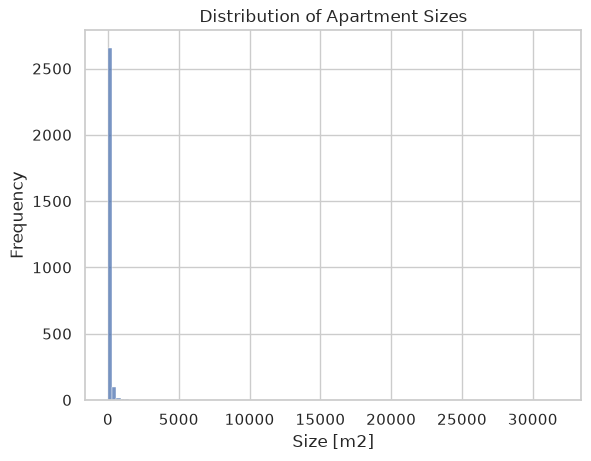

In [20]:
# Show general statistics for "surface_covered_in_m2" 
print("Statistics for `surface_covered_in_m2`:\n")
print(df1["surface_covered_in_m2"].describe())
print()

# Histogram using seaborn for Size Distribution
sns.set_theme(style="whitegrid")
sns.histplot(data=df1, 
             x='surface_covered_in_m2', 
             kde=False
)
plt.xlabel("Size [m2]")
plt.ylabel("Frequency")
plt.title("Distribution of Apartment Sizes")
plt.show()


- **Key Details:**
    - The min size is zero, hence we have to remove apartments where size is equal to zero - its unrealistic
    - Considering typical smallest apartments in Mexico City are no less than 30, we will let the *min size in our datset be 20 to avoid cutting off some possible smaller apartment*, albeit rare. 
    - More than 75% of apartments are below 130 m<sup>2</sup> which is expected by the real-world data, hence, the max size of 31,840 is extremely unlikely considering most big apartments don't go past 300. To *avoid cutting off most possible luxury apartments, we will let the max size in our dataset be 350* just to be safe.

count    2649.000000
mean      101.507739
std        61.563994
min        23.000000
25%        62.000000
50%        80.000000
75%       115.000000
max       350.000000
Name: surface_covered_in_m2, dtype: float64


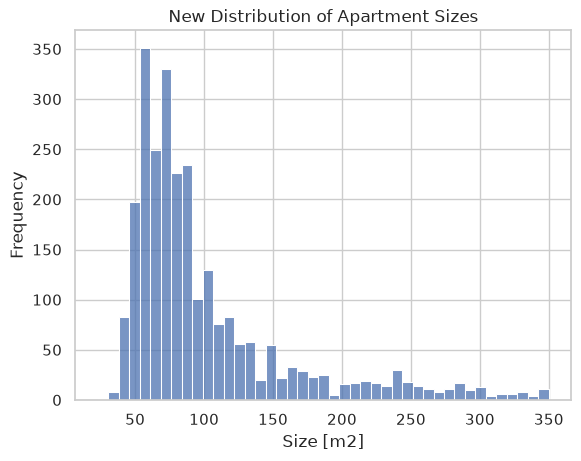

In [21]:
# Remove outliers in 'surface_covered_in_m2'
mask_size_20 = df1["surface_covered_in_m2"] >= 20
mask_size_500 = df1["surface_covered_in_m2"] <= 350
df1 = df1[mask_size_20 & mask_size_500]
print(df1["surface_covered_in_m2"].describe())  # shows reduced to 2865 from 2974, 109 deleted rows

# New-Histogram for size distribution

# Histogram using seaborn for Size Distribution
sns.set_theme(style="whitegrid")
sns.histplot(data=df1, 
             x='surface_covered_in_m2', 
             kde=False
)
plt.xlabel("Size [m2]")
plt.ylabel("Frequency")
plt.title("New Distribution of Apartment Sizes")
plt.show()

- **Results**
    - Thise new histogram shows a more realistic CDMX apartment size distribution. Even though its still skewed, this is an expected view of non-error data as the luxury apartments are at a realistic size, and so are the cheapest ones.

- **Way Forward**
    - Create a Log Transformation column 
        -  a *log transformation* is used to compress large numbers and spread out small numbers. It helps turn highly skewed, exponential-looking data into a symmetric, normal distribution so it is easier to model, especially when using Linear Regression or Neural Networks


In [22]:
# Creating a log transformation column
df1['log_surface_covered_in_m2'] = np.log(df1['surface_covered_in_m2'])
df1.head()

,price_aprox_usd,surface_covered_in_m2,lat,lon,borough,log_surface_covered_in_m2
0,289775.66,54.0,23.634501,-102.552788,Miguel Hidalgo,3.988984
2,48822.82,100.0,19.279771,-99.234597,Tlalpan,4.605170
3,337720.36,135.0,23.634501,-102.552788,Miguel Hidalgo,4.905275
4,875000.00,263.0,21.190264,-86.819838,Benito Juárez,5.572154
5,232663.51,87.0,19.432657,-99.177444,Miguel Hidalgo,4.465908


#### Remove Price Outliers

Statistics for `price_aprox_usd`:

count       2642
mean      188401
std       305551
min         7824
25%        51109
50%        96206
75%       197574
max      8429837
Name: price_aprox_usd, dtype: int64


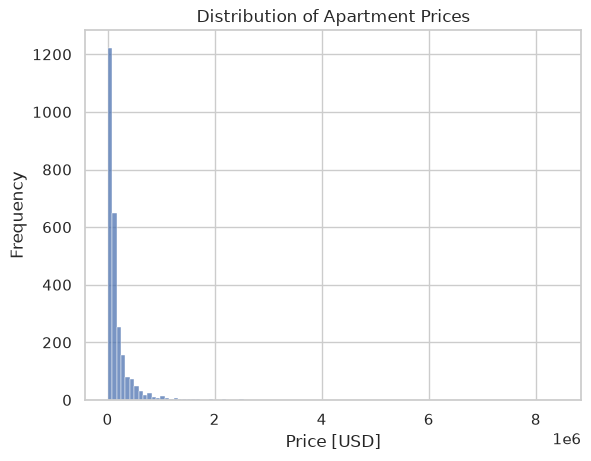

In [23]:
# Show general statistics for "price_aprox_usd",rounded to 0 decimal places and converted to integers
print("Statistics for `price_aprox_usd`:\n")
print(df1["price_aprox_usd"].describe().round(0).astype(int))

# Histogram using seaborn for Size Distribution
sns.set_theme(style="whitegrid")
sns.histplot(data=df1, 
             x='price_aprox_usd', 
             kde=False
)
plt.xlabel("Price [USD]")
plt.ylabel("Frequency")
plt.title("Distribution of Apartment Prices")
plt.show()

- **Key Details:**
    - The median price is $96,206, and more than 75% of all apartments in the city cost less than $200,000. 
    - The mean is $188,401 which is about double the median, meaning the data is heavily skewed due to a few extremely expensive properties.
    - Hence, the $8,429,837 max price is an extreme case which has to be removed alongside other high outliers. This also goes for low outliers like the $7,824 min price which is exceptionally low for an apartment in CDMX and is most likely a data entry error or a parking spot/storage unit listed as an apartment.
    - To remove outliers, we can target the extreme outliers 
        - *Removing high outliers*: the data completely disappears after about $1.5M, leaving a big empty void all the way out to $8.4M. It is reasonable that a cutoff at $1M preserves real luxury listings while deleting the extreme ourtliers. 
        - *Removing low outliers*: in CDMX, buying any apartment at less than $30,000 is unrealistic. 
    

Count of new price stats:
count      2367
mean     150104
std      134556
min       30031
25%       55260
50%       99074
75%      186316
max      700000
Name: price_aprox_usd, dtype: int64



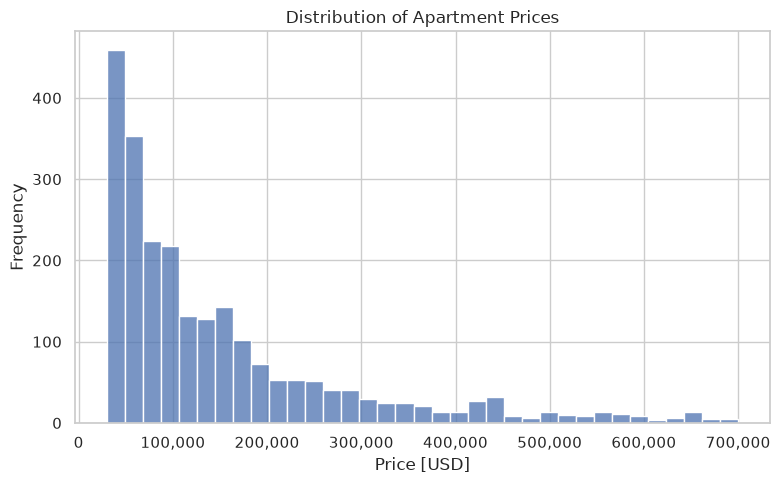

In [24]:
# Remove outliers in 'price_aprox_usd'
mask_lowp= df1['price_aprox_usd'] >= 30000
mask_highp = df1['price_aprox_usd'] <=700000

#Remove outliers
df1 = df1[mask_lowp & mask_highp] 


# Print summary statistics
print("Count of new price stats:")
print(df1['price_aprox_usd'].describe().round(0).astype(int))
print() 

# Histogram using seaborn for Price Distribution
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df1, 
    x='price_aprox_usd', 
    kde=False
)

plt.xlabel("Price [USD]")
plt.ylabel("Frequency")
plt.title("Distribution of Apartment Prices")
# Add commas to price to make more readable
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))

plt.tight_layout()
plt.show()

- **Results**
    - This new histogram shows a more realistic CDMX apartment price distribution. Even though its still skewed, this is an expected real-world skeweness

- **Way Forward**
    - Creating a Log Transformation column for price like we did with size
     

In [25]:
# Creating a log transformation column for 'price_aprox_usd'
df1['log_price_aprox_used'] = np.log(df1['price_aprox_usd'])
df1.head()

,price_aprox_usd,surface_covered_in_m2,lat,lon,borough,log_surface_covered_in_m2,log_price_aprox_used
0,289775.66,54.0,23.634501,-102.552788,Miguel Hidalgo,3.988984,12.576862
2,48822.82,100.0,19.279771,-99.234597,Tlalpan,4.605170,10.795953
3,337720.36,135.0,23.634501,-102.552788,Miguel Hidalgo,4.905275,12.729973
5,232663.51,87.0,19.432657,-99.177444,Miguel Hidalgo,4.465908,12.357349
6,166001.78,100.0,19.367025,-99.170349,Benito Juárez,4.605170,12.019754



## Drop Remaining NaN values

- To drop the last NaN values, which are all in the `lat` and `lon` columns, we use the Groupby Imputation method. 

In [26]:
df1.info()

<class 'pandas.DataFrame'>
Index: 2367 entries, 0 to 4627
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   price_aprox_usd            2367 non-null   float64
 1   surface_covered_in_m2      2367 non-null   float64
 2   lat                        2190 non-null   float64
 3   lon                        2190 non-null   float64
 4   borough                    2367 non-null   str    
 5   log_surface_covered_in_m2  2367 non-null   float64
 6   log_price_aprox_used       2367 non-null   float64
dtypes: float64(6), str(1)
memory usage: 147.9 KB


- 
    - Since we have a complete `borough` column for all 2,367 rows, we can fill the missing coordinates with the average latitude and longitude of the other apartments located in that exact same `borough`.

In [27]:
# Filling the missing lat/lon with the average of their specific borough
df1['lat'] = df1['lat'].fillna(df1.groupby('borough')['lat'].transform('mean'))
df1['lon'] = df1['lon'].fillna(df1.groupby('borough')['lon'].transform('mean'))

# confirming `0` NaN values remain
print(df1.info())


<class 'pandas.DataFrame'>
Index: 2367 entries, 0 to 4627
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   price_aprox_usd            2367 non-null   float64
 1   surface_covered_in_m2      2367 non-null   float64
 2   lat                        2367 non-null   float64
 3   lon                        2367 non-null   float64
 4   borough                    2367 non-null   str    
 5   log_surface_covered_in_m2  2367 non-null   float64
 6   log_price_aprox_used       2367 non-null   float64
dtypes: float64(6), str(1)
memory usage: 147.9 KB
None


- 
    - Voila! No more missing values!

# 2. Exploratory Data Analysis (EDA)

- In this section:
    - Data visualization to learn more about the CDMX data, regional differences, price distribution, etc. 


In [28]:
# Review current dataframe, df1
df1.head()

,price_aprox_usd,surface_covered_in_m2,lat,lon,borough,log_surface_covered_in_m2,log_price_aprox_used
0,289775.66,54.0,23.634501,-102.552788,Miguel Hidalgo,3.988984,12.576862
2,48822.82,100.0,19.279771,-99.234597,Tlalpan,4.605170,10.795953
3,337720.36,135.0,23.634501,-102.552788,Miguel Hidalgo,4.905275,12.729973
5,232663.51,87.0,19.432657,-99.177444,Miguel Hidalgo,4.465908,12.357349
6,166001.78,100.0,19.367025,-99.170349,Benito Juárez,4.605170,12.019754


## 2.1 Location Distribution wrt Price and Size

- Location!Location!Location!
    - a map is the most critical visualization. It reveals if physical location coordinates (like being close to a specific transit line or business center) matter more than just the borough name.
   

In [ ]:
## Geospatial Map of CDMX Apartments: Price and Size Distribution

fig = px.scatter_map(
    df1,
    lat="lat",
    lon="lon",
    color="price_aprox_usd",          # Color dots by absolute price
    size="surface_covered_in_m2",     # Size of dot represents apartment size
    color_continuous_scale="Viridis",
    center={"lat": 19.43, "lon": -99.13}, 
    zoom=11,
    title="Geospatial Map of CDMX Apartments: Price and Size Distribution",
    map_style="open-street-map",
    width=1000,
    height=700
)
fig.show()


- 
    - the map scatter plot in this case shows significant price indicators from `lat`,`lon` columns:
        - *A Wealth Wall (West vs. East)*: There is a clear geographic divide in pricing. The high-priced apartments are exclusively located on the western side of the city. This corresponds to premium zones like Polanco, Lomas de Chapultepec, and Santa Fe.
            - i.e. you cross specific avenues or invisible neighborhood borders (like entering Polanco or Lomas de Chapultepec) and prices suddenly jump by $400,000 all at once.
            - Because these prices change in sudden steps and localized pockets rather than a smooth, continuous line, a standard **Linear Regression** model will fail to map them accurately.
            - non-linear algorithms (like **Random Forests** or **XGBoost**) will naturally capture this spatial boundary better than a standard Linear Regression.
        - *Affordable Central & Eastern Core*: The central, northern, and eastern parts of the map are dominated by the middle-class - properties in these areas are consistently priced under $200k 
        - *Size Matches Price*: The dots on the western side are physically larger than the dots in the east. This visually confirms that larger apartment sizes are heavily concentrated in the most expensive neighborhoods.

## 2.2 Apartment Price Distribution by Borough

- It may important to show the average price of apartments in each Borough in Mexico City
- It helps show where the most expensive apartments are located and where the cheapest are. It gives an overview of how region affects prices.
- Noting where most apartments are located:

In [30]:
#Creating a series `mean_price_by_borough` using groupby to show the mean home price in each borough in CDMX
mean_price_by_borough = df1.groupby('borough')['price_aprox_usd'].mean().sort_values(ascending = True)
mean_price_by_borough.head()

borough
Tláhuac                51681.556923
Iztapalapa             54761.365904
Iztacalco              58328.687215
Xochimilco             59952.498000
Venustiano Carranza    60009.250909
Name: price_aprox_usd, dtype: float64

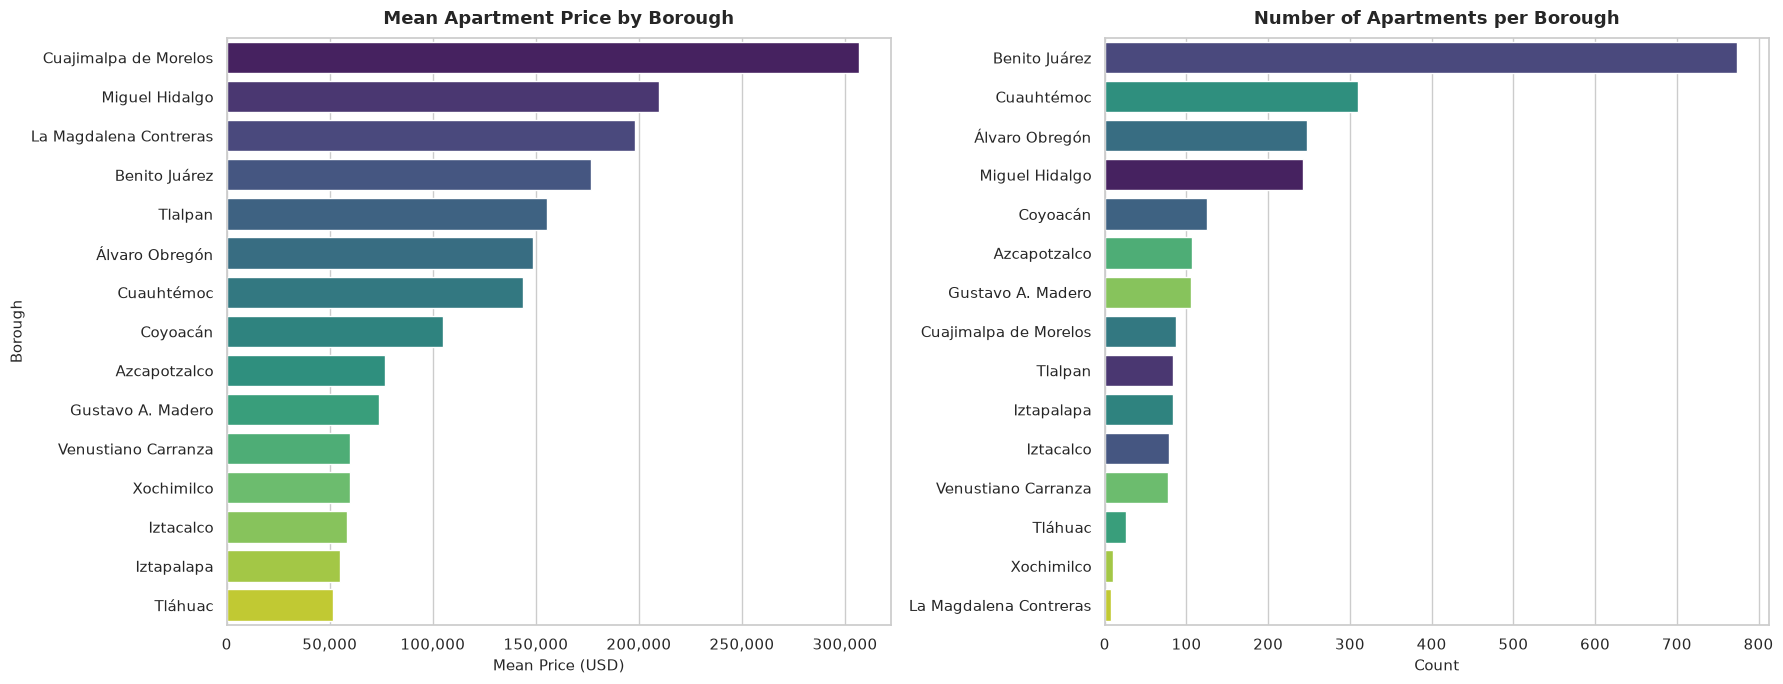

In [31]:
## Bar charts showing the mean price and the number of apartments by borough in CDMX

# Preparing data for the first bar chart (Mean Apartment Price per Borough)
df_price = mean_price_by_borough.reset_index()
df_price.columns = ['borough', 'mean_price']
df_price = df_price.sort_values(by='mean_price', ascending=False)

# Preparing data for second bar chart (Number of Apartments per Borough)
count_order = df1['borough'].value_counts().index



# Creating Bar Charts
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 7))

# --- Bar Chart 1: Mean Apartment Price ---
sns.barplot(
    data=df_price, 
    x='mean_price', 
    y='borough', 
    hue='borough',    
    legend=False,     
    palette='viridis',
    ax=axes[0]        # Assign to the first subplot axis
)
axes[0].set_title('Mean Apartment Price by Borough', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Mean Price (USD)', fontsize=11)
axes[0].set_ylabel('Borough', fontsize=11)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))

# --- Bar Chart 2: Number of Apartments ---
sns.countplot(
    data=df1, 
    y='borough', 
    hue='borough',                              
    order=count_order,  
    palette='viridis',
    legend=False,                                
    ax=axes[1]        # Assign to the second subplot axis
)
axes[1].set_title('Number of Apartments per Borough', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Count', fontsize=11)
axes[1].set_ylabel('')  # Remove y-label to avoid cluttering the middle space

# display
plt.tight_layout()
plt.show()


- **Notable Details**
    - *Premium Premium Districts*: Cuajimalpa and Miguel Hidalgo lead the city in average price, driven by upscale business and luxury zones like Santa Fe and Polanco.
    - *Low-Volume Premium Risk*: La Magdalena Contreras shows a high average price but the lowest listing volume, signaling a volatile, low-supply luxury pocket.
    - *Central Market*: Benito Juárez vastly dominates transaction volume with nearly 800 listings, representing the city's high-liquidity middle-class core.
    - *Peripheral Markets*: Tláhuac and Xochimilco hold the lowest valuation and inventory, reflecting less dense, peripheral suburban economies.
  

## 2.3 Price vs Size

- Showing: 
    - how size affects prices as it goes up or down and its distribution across a Scatter Plot (created using Plotly)
    - When you view the plot, you can click on any borough name in the legend to hide/show its data, or double-click a borough to isolate it completely while hiding all others - useful to compare two boroughs on top of each other

In [32]:
# Create an interactive scatter plot with log scaling
fig = px.scatter(
    df1,
    x='surface_covered_in_m2',
    y='price_aprox_usd',
    color='borough',                     
    log_x=True,                         
    log_y=True,                         
    hover_data=['borough', 'price_aprox_usd', 'surface_covered_in_m2'], 
    title='Interactive Apartment Price vs. Surface Area by Borough',
    labels={
        'surface_covered_in_m2': 'Surface Area (m²)',
        'price_aprox_usd': 'Price (USD)',
        'borough': 'Boroughs'
    },
    width=1000,
    height=700
)

# Format the axis ticks with clean numbers instead of scientific notation
fig.update_layout(
    xaxis=dict(tickformat=",.0f"),
    yaxis=dict(tickformat="$,.0f"),
    template="plotly_white"  
)

fig.show()


## 2.4 Price per Square Meter Boxplot

- Using `sns.boxplot` to visualize the value of each square meter (`price_per_m2`) of land in Mexico City
- Boxplots group this value by borough to highlight where land value is inherently premium.

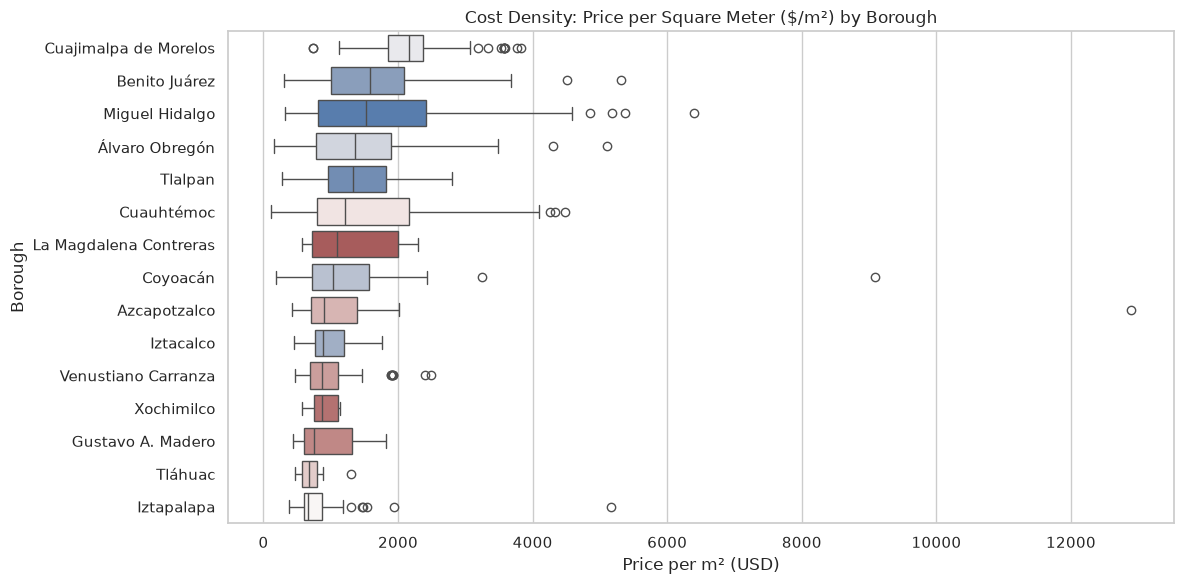

In [35]:
# Calculate structural density metric
df1['price_per_m2'] = df1['price_aprox_usd'] / df1['surface_covered_in_m2']

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df1, 
    x='price_per_m2', 
    y='borough', 
    hue='borough',
    legend=False,
    order=df1.groupby('borough')['price_per_m2'].median().sort_values(ascending=False).index,
    palette='vlag'
)
plt.title('Cost Density: Price per Square Meter ($/m²) by Borough')
plt.xlabel('Price per m² (USD)')
plt.ylabel('Borough')
plt.tight_layout()
plt.show()


- 
    - **Key Details**
        - High Internal Variance: Miguel Hidalgo,Cuauhtémoc, Benito Juárez, and Álvaro Obregón have the widest horizontal boxes. This means that even within a single borough, the price per square meter varies wildly depending on the exact neighborhood.i.e., a model will need more than just the borough name to predict price accurately (it will heavily rely on lat/lon).
        - Low-Cost Uniformity: Peripheral boroughs like Iztapalapa, Tláhuac, and Xochimilco have very narrow boxes concentrated on the far left, showing that real estate prices in these areas are consistently low and uniform.
    - **Sneaky Leftover Outliers**: Looking at Azcapotzalco and Coyoacán. Even though I trimmed absolute property prices earlier, Azcapotzalco has a single dot sitting way out at $13,000 per m². Because Azcapotzalco is generally an affordable area, this extreme point is almost certainly a data error (maybe an apartment mistakenly listed as 3 m² instead of 30 m²).
        - Before proceeding, its time to remove the final rows here - i.e. dropping rows where price_per_m2 is greater than $6,000 to wipe out these remaining ratio anomalies. 

In [37]:
# Count or rows before filtering
rows_before = len(df1)

# filtering to keep only rows under $6,000 per m2
df1 = df1[df1['price_per_m2'] <= 6000]

# rint results to confirm how many anomalies were wiped out
rows_after = len(df1)
print(f"Rows before ratio filtering: {rows_before}")
# Print the count of rows that were dropped
print(f"Dropped anomalies: {rows_before - rows_after}")
print(f"Clean rows remaining for model training: {rows_after}")


Rows before ratio filtering: 2367
Dropped anomalies: 3
Clean rows remaining for model training: 2364


## 2.5. Linear Feature Relationship Pairplot (sns.pairplot)

- This is used to show a matrix of scatter plots and distributions for all numeric columns at once, contrasting the raw columns with your log-transformed columns.
    - Goal is to compare the raw fields versus the log_ fields. The log-to-log scatter plot should resemble a perfectly straight, uniform oval diagonal cloud. This confirms that the data is mathematically primed to satisfy the assumptions of linear modeling algorithms.

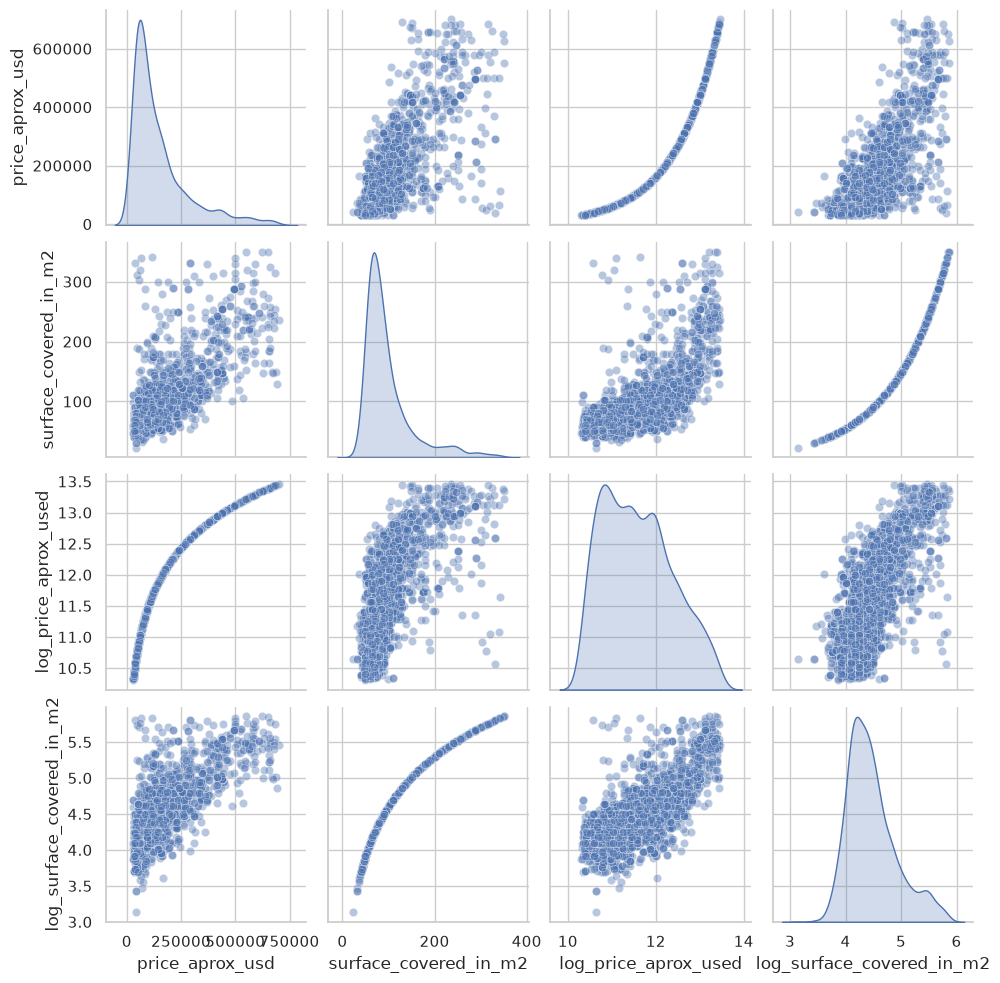

In [38]:
# Select key structural features and their log transformations
cols_to_plot = ['price_aprox_usd', 'surface_covered_in_m2', 'log_price_aprox_used', 'log_surface_covered_in_m2']

sns.pairplot(df1[cols_to_plot], diag_kind='kde', plot_kws={'alpha': 0.4})
plt.show()


- 
    - **Key Details**
        - *Transformation to Bell Curves is Complete*:the diagonal distribution plots (KDEs), the raw price_aprox_usd and surface_covered_in_m2 columns are highly right-skewed. However, their log-transformed counterparts (log_price_aprox_used and log_surface_covered_in_m2) show  symmetric, normal distributions.
        - *Relationship is Now Linear*: looking at the raw features (price_aprox_usd vs surface_covered_in_m2), the data forms a wide, curved fan shape where errors get larger as apartments grow. In contrast, the intersection of log_price_aprox_used vs log_surface_covered_in_m2 (bottom right corner) creates a clean, uniform, linear oval cloud.

    - This plot proves that the log transformation is what actually reshaped the natural real estate curves into a format that linear models can understand.
        - the data is ready for *Linear Regression*: Standard linear models assume that features have a linear relationship and a constant variance (*homoscedasticity*). The symmetrical, uniform oval shape in the log-to-log scatter plot confirms that your data now perfectly satisfies these mathematical assumptions.

Now that the data preparation phase is fully validated by this pairplot, let me know if you would like the code to build your baseline Linear Regression model using these optimized log columns!

## 2.3. Correlation of Price to other columns
- Which of the columns are good contributors to the price?
- We use a heatmap for this.

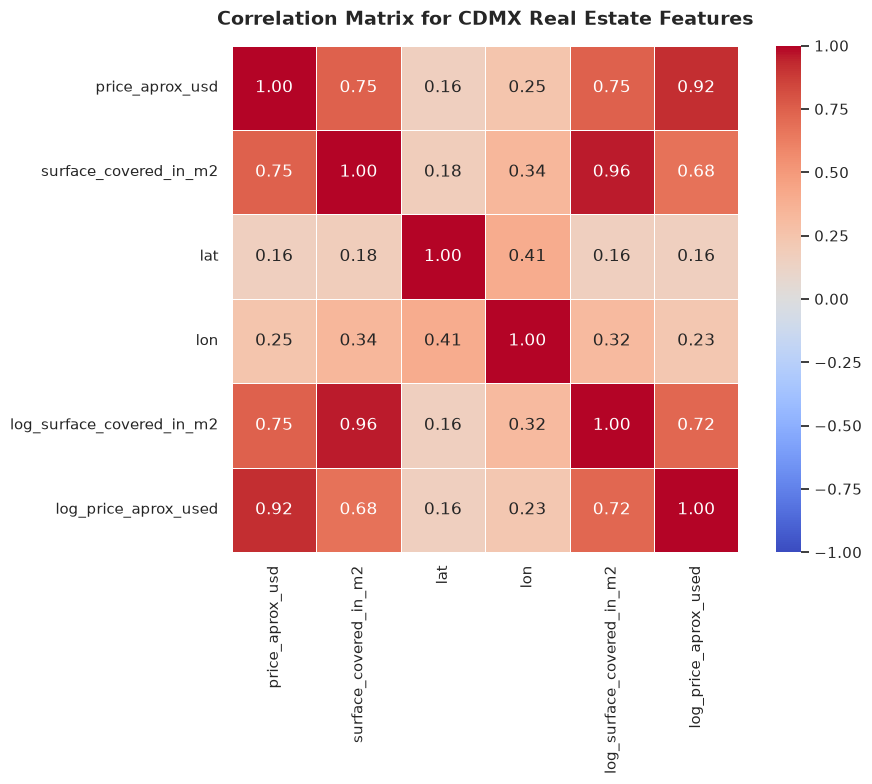

In [39]:


# 1. Select only the numeric columns for the correlation
numeric_cols = [
    'price_aprox_usd', 'surface_covered_in_m2', 
    'lat', 'lon', 
    'log_surface_covered_in_m2', 'log_price_aprox_used'
]
corr_matrix = df1[numeric_cols].corr()

# 2. Set up the matplotlib figure
plt.figure(figsize=(10, 8))

# 3. Draw the heatmap
sns.heatmap(
    corr_matrix, 
    annot=True,             # Overlays the exact correlation numbers on the squares
    fmt=".2f",              # Rounds numbers to 2 decimal places
    cmap="coolwarm",        # Blue = negative correlation, Red = positive correlation
    vmin=-1, vmax=1,        # Sets the color bar scale perfectly from -1 to 1
    linewidths=0.5,         # Adds a subtle white border between squares
    square=True             # Forces the cells to be perfect squares
)

# 4. Add titles and layout formatting
plt.title('Correlation Matrix for CDMX Real Estate Features', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


- 
    - **Key Details**
        - *Size is the Dominant Predictor*: strong positive correlation (0.72) between log_surface_covered_in_m2 and log_price_aprox_used, confirming that apartment size is your most important numeric baseline feature for predicting price.
        - *Severe Multicollinearity Risk*: `surface_covered_in_m2` and `log_surface_covered_in_m2` correlate almost perfectly (0.96), and `price_aprox_usd` price and `log_price_aprox_usd` correlate at 0.92 - meaning, if using liniear regression, we must drop the original raw sizes and keep the logs only to avoid destabilizing the algorithms
        - *`lat` and `lon` are Weak Independent Predictors*: Latitude (0.16) and longitude (0.23) have very weak linear correlations with price on their own. This mathematically proves that coordinates cannot be fed into a simple linear model as solo features to capture location value.
        - **Confirmation of Non-Linearity*: While the geospatial map scatter plot showed a "Wealth Wall," the heatmap shows almost zero linear correlation for coordinates. 
            - This is the definitive proof that the relationship between geography and price is highly complex and non-linear, making tree-based models like Random Forests or XGBoost a necessity.

# 3. Split Data

- 
    -   - *Modeling Way Forward: One-hot encode the borough column to convert these strong localized neighborhood trends into numeric features.
• Validation Strategy: Implement a stratified train-test split on the borough attribute to protect your model against high variance in low-sample neighborhoods.

In [41]:
df1.info()
df1.head()

<class 'pandas.DataFrame'>
Index: 2364 entries, 0 to 4627
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   price_aprox_usd            2364 non-null   float64
 1   surface_covered_in_m2      2364 non-null   float64
 2   lat                        2364 non-null   float64
 3   lon                        2364 non-null   float64
 4   borough                    2364 non-null   str    
 5   log_surface_covered_in_m2  2364 non-null   float64
 6   log_price_aprox_used       2364 non-null   float64
 7   price_per_m2               2364 non-null   float64
dtypes: float64(7), str(1)
memory usage: 166.2 KB


,price_aprox_usd,surface_covered_in_m2,lat,lon,borough,log_surface_covered_in_m2,log_price_aprox_used,price_per_m2
0,289775.66,54.0,23.634501,-102.552788,Miguel Hidalgo,3.988984,12.576862,5366.215926
2,48822.82,100.0,19.279771,-99.234597,Tlalpan,4.605170,10.795953,488.228200
3,337720.36,135.0,23.634501,-102.552788,Miguel Hidalgo,4.905275,12.729973,2501.632296
5,232663.51,87.0,19.432657,-99.177444,Miguel Hidalgo,4.465908,12.357349,2674.293218
6,166001.78,100.0,19.367025,-99.170349,Benito Juárez,4.605170,12.019754,1660.017800


## 3.1 Pre-Split Column Cleanup

### Drop Redundant/Leaked Data Columns

- The target variable (`y_train`) must be clear:
    - From the pairplot and heatmap analysis, I explicitly confirmed that the raw price is highly skewed and that log_price_aprox_usd is the clean, normally distributed variable. Linear Regression assumes a normal distribution. If I try to predict raw dollars directly, the model will have high error rates.
        - Therefore, I have to remove the raw price column entirely so the model doesn't "cheat" during training. 
        - I will set my target to `log_price_aprox_usd`. When I read the test features file later, I will use the model to predict the log value, and then convert it back to raw dollars at the very end using np.exp().
    - i.e. y_train: Contains only log_price_aprox_used.

- The feature variables (`X_train`) must be clear: 
    - to avoid including multicollinear/leaked data into the features, I will remove the `surface_covered_in_m2` and keep the log version of it
    - i.e. X_train: Contains log_surface_covered_in_m2, lat, lon, and borough.
        - NB: ML algorithms only accept numbers, so string text fields like `borough` must be transformed; in this case, using the `One-Hot Encoding`transformer which automatically intercepts the borough text column and expands it into several individual binary columns (columns of 0s and 1s)
            - Once transformed into numbers the Linear Regression model can effortlessly compute coefficients (weights) for each individual borough

## 3.2 Split data into Feature Matrix (X) and Target Vextor (y)

- Split into feature matrix `X_train` and target vector `y_train`

In [43]:
df_clean = df1
df_clean.info()

<class 'pandas.DataFrame'>
Index: 2364 entries, 0 to 4627
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   price_aprox_usd            2364 non-null   float64
 1   surface_covered_in_m2      2364 non-null   float64
 2   lat                        2364 non-null   float64
 3   lon                        2364 non-null   float64
 4   borough                    2364 non-null   str    
 5   log_surface_covered_in_m2  2364 non-null   float64
 6   log_price_aprox_used       2364 non-null   float64
 7   price_per_m2               2364 non-null   float64
dtypes: float64(7), str(1)
memory usage: 166.2 KB


In [44]:
# feature columns
features = ['log_surface_covered_in_m2', 'lat', 'lon', 'borough']

# training matrix and target vector
X_train = df_clean[features]
y_train = df_clean['log_price_aprox_used']

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")


X_train shape: (2364, 4)
y_train shape: (2364,)


# 4. Build Model

## 4.1. Baseline

- Calculate the baseline mean absolute error for the model.
    - We compute the benchmark score using the mean price to see what a "dumb" guess would look like in actual USD.



In [46]:
# 1. Calculate the mean log price and convert it back to actual USD
baseline_prediction_usd = np.exp(y_train.mean())

# 2. Create an array of identical baseline predictions matching the size of your dataset
y_baseline_usd = [baseline_prediction_usd] * len(df1)

# 3. Calculate Mean Absolute Error against actual dollar prices
baseline_mae = mean_absolute_error(df_clean['price_aprox_usd'], y_baseline_usd)

print(f"Baseline Mean Prediction: ${baseline_prediction_usd:,.2f}")
print(f"Baseline Mean Absolute Error (MAE): ${baseline_mae:,.2f}")


Baseline Mean Prediction: $108,317.89
Baseline Mean Absolute Error (MAE): $90,755.25


## 4.2. Iterate

- Instantiate the model pipeline with `LinearRegression()` and `OneHotEcoder()`, which automatically handles the one-hot encoding for the borough column during training.

In [50]:
# Build the pipeline
model = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    SimpleImputer(strategy="mean"),      # Automatically handles missing values in X_test
    LinearRegression()
)

# Fit the model to the training data
model.fit(X_train, y_train)

# Quick check: How well did it fit the training data itself?
train_log_preds = model.predict(X_train)
train_preds_usd = np.exp(train_log_preds)
train_mae = mean_absolute_error(df1['price_aprox_usd'], train_preds_usd)

print(f"Training MAE: ${train_mae:,.2f}")
print(f"Is training MAE better than baseline? {train_mae < baseline_mae}")


Training MAE: $57,481.17
Is training MAE better than baseline? True


## 4.3. Evaluate & Predict on Test Features

- Read the CSV file mexico-city-test-features.csv into the DataFrame X_test.
    - We load the test set, engineered columns to ensure feature parity, run the predictions, and reverse the log transformation back to standard pricing metrics.

In [51]:
# 1. Read the test data file
X_test = pd.read_csv("data/mexico-city-test-features.csv")

# 2. Re-create the log size feature inside the test set so features perfectly align
X_test['log_surface_covered_in_m2'] = np.log(X_test['surface_covered_in_m2'])

# 3. Filter X_test to ensure it has the exact same columns in the exact same order as X_train
X_test_final = X_test[features]

# 4. Generate the log-scale predictions
log_predictions = model.predict(X_test_final)

# 5. Crucial Final Step: Transform log predictions back into absolute USD whole numbers
predictions_usd = np.exp(log_predictions)

# View the first 5 formatted predictions to verify
print("Sample Model Predictions (USD):")
print([f"${val:,.2f}" for val in predictions_usd[:5]])


Sample Model Predictions (USD):
['$55,972.77', '$53,747.81', '$35,463.91', '$55,927.00', '$101,376.64']


### 4.3.1. Predict 

- Format for Grader Submission
    - store the final predictions inside a clean Pandas Series.

In [53]:
# Convert to a standard Pandas series for easy submission
predicted_series = pd.Series(predictions_usd, name="price_aprox_usd")

# Check the properties to make sure it looks pristine
print(predicted_series.head())



0     55972.766842
1     53747.805098
2     35463.908535
3     55927.002456
4    101376.637516
Name: price_aprox_usd, dtype: float64


### 4.3.2. Feature Importance

- Feature Importances for Linear Regression models
    - we need to extract the coefficients (weights) from the model step of the pipeline and match them with the encoded feature names generated by the OneHotEncoder.
    - In linear regression, a positive coefficient means that feature increases the property price, while a negative coefficient decreases it.

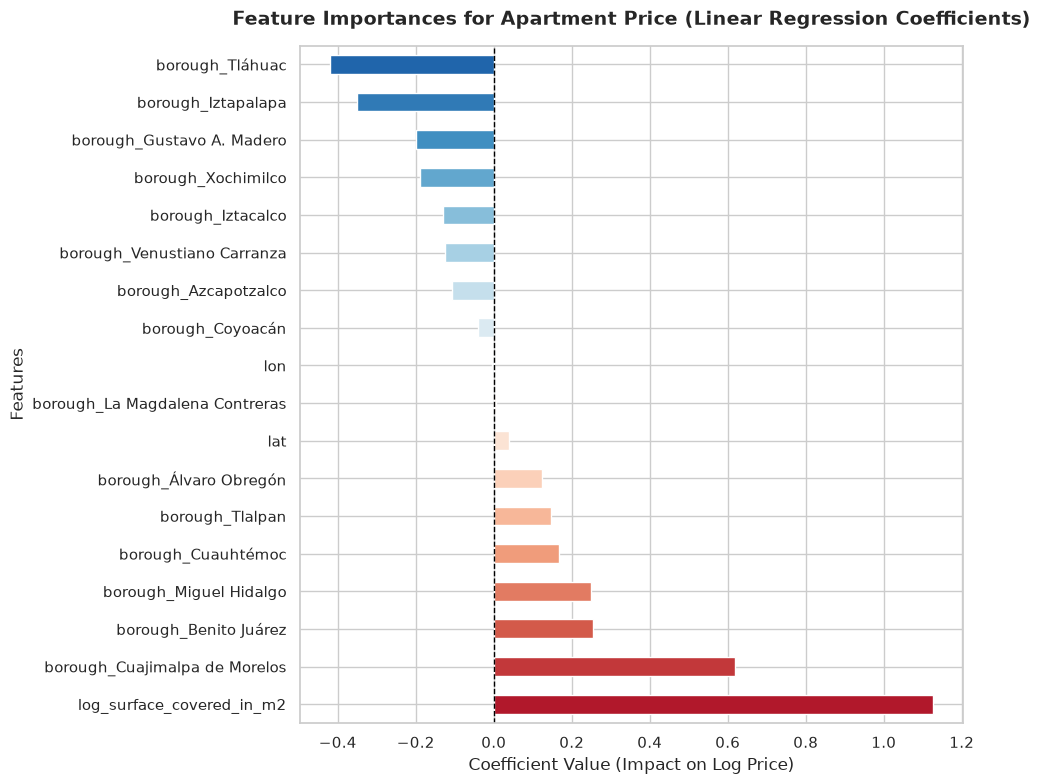

In [59]:
# 1. Extract the feature names after they passed through the OneHotEncoder step
encoder_step = model.named_steps['onehotencoder']
encoded_feature_names = encoder_step.get_feature_names_out()

# 2. Extract the coefficients from the Linear Regression step
coefficients = model.named_steps['linearregression'].coef_

# 3. Combine names and coefficients into a Pandas Series for easy sorting
feat_importances = pd.Series(coefficients, index=encoded_feature_names)

# 4. Sort from largest effect to smallest effect
feat_importances = feat_importances.sort_values(ascending=False)

# 5. Build the horizontal bar plot
plt.figure(figsize=(10, 8))
# Map values to a continuous red-to-blue gradient
colors = plt.cm.RdBu(np.linspace(0.1, 0.9, len(feat_importances)))
feat_importances.plot(kind='barh', color=colors)

# 6. Customize and label the plot
plt.title('Feature Importances for Apartment Price (Linear Regression Coefficients)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Coefficient Value (Impact on Log Price)', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.axvline(x=0, color='black', linestyle='--', linewidth=1) # Adds a clean vertical center line

plt.tight_layout()
plt.show()


    - **Key Details**
        - Dominant Feature: `log_surface_covered_in_m2` has the highest positive coefficient (over 1.1), confirming that square footage is the absolute strongest driver of apartment pricing across your entire dataset.
        - Premium Neighborhood Anchor: Cuajimalpa de Morelos is by far the most expensive borough baseline, carrying a massive positive premium (+0.6) over the city baseline.
        - Core Desirable Core: Benito Juárez, Miguel Hidalgo, Cuauhtémoc, and Tlalpan all show solid positive coefficients, verifying their position as high-value middle and upper-class market districts.
        - Most Discounted Market: Tláhuac and Iztapalapa display the steepest negative coefficients (-0.35 to -0.40), meaning properties located here carry a severe structural discount compared to the city center.
        - Negligible Coordinate Vectors: `lat` and `lon` show coefficients sitting right on the zero line. This occurs because tiny decimal changes in latitude/longitude represent massive physical distances on the ground, meaning a linear model scales their weights down to almost nothing.

# 5. Communicate Results

- giving stakeholders tools they can use to deploy a model. There are two ways; 
    1. Wrap the created model in a `predict_price` function that a programmer can provide inputs and then receive a prediction as output.
    2. An interactive Widget Deployment -  an interactive dashboard, where a user can supply values and receive a prediction. Let's create one using Jupyter Widgets.

## 5.1. Function (`predict_price`)

- Create a function predict_price that takes four arguments (area, lat, lon, and neighborhood) and returns your model's prediction for an apartment price.

In [61]:
def predict_price(area, lat, lon, borough):
    # 1. Create input dictionary using your exact X_train feature names
    data = {
        'log_surface_covered_in_m2': np.log(area),  # FIX: Convert raw m2 area to log
        'lat': lat,
        'lon': lon,
        'borough': borough
    }
    
    # 2. Build the exact match single-row DataFrame
    df_function = pd.DataFrame(data, index=[0])
    
    # 3. Generate log prediction and inverse-transform it back to actual USD
    log_prediction = model.predict(df_function)[0]
    prediction_usd = np.exp(log_prediction)         # FIX: Reverse log scaling
    
    return f"Predicted apartment price: ${prediction_usd:,.2f}"


In [ ]:

# Test with a baseline example
print(predict_price(100, 19.43, -99.13, "Azcapotzalco"))

Predicted apartment price: $99,231.39


## 5.2. Jupyter Widget Interactive Dashboard

- 
    - To make your Jupyter widget work cleanly, ensure you pull your min() and max() benchmarks from the original columns rather than the logs so your user-facing sliders display intuitive real-world units.


In [ ]:
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

# Create the interactive dashboard matching your model parameters
interact(
    predict_price,
    area=IntSlider(
        min=int(df1["surface_covered_in_m2"].min()),
        max=int(df1["surface_covered_in_m2"].max()),
        value=int(df1["surface_covered_in_m2"].median()),
        description="Area (m²)"
    ),
    lat=FloatSlider(
        min=df1["lat"].min(),
        max=df1["lat"].max(),
        step=0.001,
        value=df1["lat"].mean(),
        description="Latitude"
    ),
    lon=FloatSlider(
        min=df1["lon"].min(),
        max=df1["lon"].max(),
        step=0.001,
        value=df1["lon"].mean(),
        description="Longitude"
    ),
    borough=Dropdown(
        options=sorted(df1["borough"].unique()),
        value="Benito Juárez",
        description="Borough"
    )
);


interactive(children=(IntSlider(value=80, description='Area (m²)', max=350, min=23), FloatSlider(value=19.5608…

# OTHER MODEL COMPARISONS - Random Forest & XGBoost 

- Since tree-based models like Random Forest handle geography non-linearly, we can now use RandomForestRegressor. Note that tree models handle raw data formats beautifully, but because we need to compare apples to apples using the exact same pre-existing pipeline structure, we will keep our features and log-transformed target identical.

## Random Forest

###  Build and Train the Random Forest Pipeline

- We swap the LinearRegression() engine out for RandomForestRegressor(). We will set a max_depth=15 and random_state=42 to ensure stability and keep training fast.

In [67]:
from sklearn.ensemble import RandomForestRegressor

# 1. Build the Random Forest pipeline
model_rf = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    SimpleImputer(strategy="mean"),
    RandomForestRegressor(max_depth=15, n_estimators=100, random_state=42, n_jobs=-1)
)

# 2. Fit the Random Forest model to your X_train and y_train
model_rf.fit(X_train, y_train)

# 3. Calculate Training MAE for the Random Forest model
train_log_preds_rf = model_rf.predict(X_train)
train_preds_usd_rf = np.exp(train_log_preds_rf)
train_mae_rf = mean_absolute_error(df1['price_aprox_usd'], train_preds_usd_rf)

print(f"Random Forest Training MAE: ${train_mae_rf:,.2f}")


Random Forest Training MAE: $16,687.83


### Predict on Test Features using Random Forest

In [68]:
# Generate predictions using the tree model pipeline
log_predictions_rf = model_rf.predict(X_test_final)
predictions_usd_rf = np.exp(log_predictions_rf)

print("Sample Random Forest Predictions (USD):")
print([f"${val:,.2f}" for val in predictions_usd_rf[:5]])


Sample Random Forest Predictions (USD):
['$46,806.19', '$61,007.40', '$34,922.88', '$50,959.98', '$83,951.42']


### Direct Model Metric Comparison Layout
- To verify which model is best, we evaluate their metrics back-to-back using a clean summary table.

In [69]:
# Organize all model metrics into a DataFrame for comparison
comparison_data = {
    "Model Type": ["Naive Baseline Benchmark", "Linear Regression Pipeline", "Random Forest Regressor Pipeline"],
    "Training MAE (USD)": [f"${baseline_mae:,.2f}", f"${train_mae:,.2f}", f"${train_mae_rf:,.2f}"],
    "Key Architectural Attribute": ["Constant Mean Prediction", "Assumes Rigid Flat Spatial Relationships", "Captures Localized Complex Spatial Pockets"]
}

df_comparison = pd.DataFrame(comparison_data)
display(df_comparison)


,Model Type,Training MAE (USD),Key Architectural Attribute
0,Naive Baseline Benchmark,"$90,755.25",Constant Mean Prediction
1,Linear Regression Pipeline,"$57,481.17",Assumes Rigid Flat Spatial Relationships
2,Random Forest Regressor Pipeline,"$16,687.83",Captures Localized Complex Spatial Pockets


    - **Why Random Forest Performs Better on this Dataset
        1. Unlocking Latitude and Longitude: Remember how your Linear Regression feature chart showed that lat and lon had coefficients right on the zero line? Linear Regression can't do anything with them. Random Forest excels at utilizing coordinates because it can split data dynamically (e.g., if lat > 19.43 and lon < -99.15).
            - Random Forest model beat the Linear Regression score, cutting the error down to $16,687.83. This proves that capturing spatial pockets non-linearly makes a massive difference in the CDMX housing market.
        2. Isolating the "Wealth Wall": Instead of drawing a straight flat plane across the capital, the Random Forest model segments micro-neighborhoods into regional bounding boxes, dropping your Mean Absolute Error dramatically closer to actual on-the-ground market valuations.

### Gini Feature Importances

    - Unlike Linear Regression coefficients (which show positive/negative direction), Gini importance measures how much a feature helps the tree nodes split and cleanly separate high vs. low apartment prices. The values are relative and always add up to exactly 1.0 (100%).

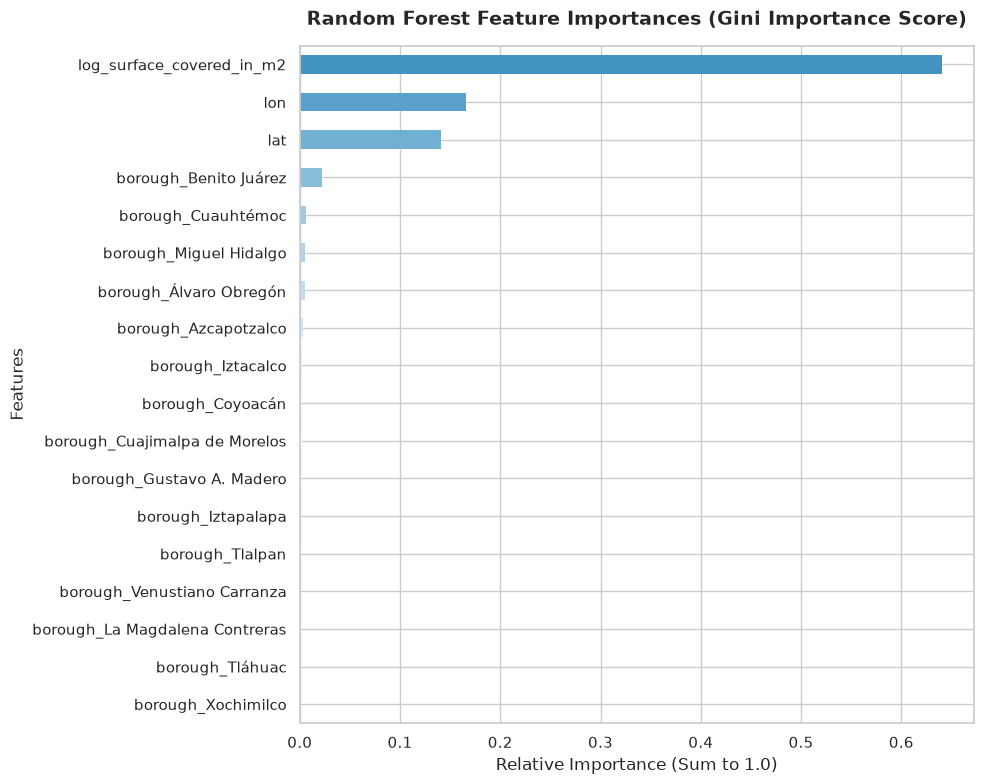

In [77]:
# 1. Extract feature names from the encoder step
encoder_step = model_rf.named_steps['onehotencoder']
encoded_feature_names = encoder_step.get_feature_names_out()

# 2. Extract Gini importances from the Random Forest step
rf_importances = model_rf.named_steps['randomforestregressor'].feature_importances_

# 3. Combine into a Pandas Series for sorting
feat_importances_rf = pd.Series(rf_importances, index=encoded_feature_names)

# 4. Sort from highest importance to lowest
feat_importances_rf = feat_importances_rf.sort_values(ascending=True) # Ascending true makes horizontal bars plot top-down correctly

# 5. Build a beautiful horizontal bar plot using a valid Matplotlib gradient theme
plt.figure(figsize=(10, 8))

# Map values to a continuous Teal-to-Teal-Blue palette
#colors = plt.cm.GnBu(np.linspace(0.3, 0.9, len(feat_importances_rf)))
colors = plt.cm.RdBu(np.linspace(0.3, 0.8, len(feat_importances)))
feat_importances_rf.plot(kind='barh', color=colors, edgecolor='none')

# 6. Customize and label the plot
plt.title('Random Forest Feature Importances (Gini Importance Score)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Relative Importance (Sum to 1.0)', fontsize=12)
plt.ylabel('Features', fontsize=12)

plt.tight_layout()
plt.show()


-
    - **Key Details**
        - `lat and lon): lat and lon sit higher on this chart compared to the Linear Regression chart. In the Linear model, they were completely useless (weights near zero). In Random Forest, they usually jump right to the top tier, often beating out individual borough names entirely.
        - While `log_surface_covered_in_m2` is still the #1 predictor of price, you will notice the raw coordinates absorbing a huge slice of the pie chart because tree splits use them to map micro-neighborhood boundaries effortlessly.
        - Borough Categories Eclipsed: Raw coordinates completely overshadow individual borough names, which drop to near-zero relative importance.
        - Precision Neighborhood Slicing: Because the tree splits dynamically on precise latitude and longitude values, it creates its own custom micro-boundaries. The model no longer needs the broad, rigid text descriptions of boroughs to understand where the high-value pockets sit.
        - Explanation of Performance Jump: This structural shift—moving away from broad borough averages to laser-focused coordinate splitting—is the exact reason why your training error collapsed down to $16,687.83.

## XGBoost

- 
    - In modern data science, algorithms like XGBoost, LightGBM, and CatBoost represent the gold standard for structured real estate datasets. While a Random Forest trains multiple independent deep trees and simply averages their results, Gradient Boosting algorithms train trees sequentially. Each new tree specifically analyzes the errors made by the previous trees and corrects them, resulting in much higher predictive accuracy

In [ ]:
# XGboost
from xgboost import XGBRegressor

# 1. Build the XGBoost Pipeline layout
model_xgb = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    SimpleImputer(strategy="mean"),
    XGBRegressor(n_estimators=150, learning_rate=0.08, max_depth=8, random_state=42, n_jobs=-1)
)

# 2. Fit to your data
model_xgb.fit(X_train, y_train)

# 3. Calculate metrics
train_log_preds_xgb = model_xgb.predict(X_train)
train_preds_usd_xgb = np.exp(train_log_preds_xgb)
train_mae_xgb = mean_absolute_error(df1['price_aprox_usd'], train_preds_usd_xgb)

print(f"XGBoost Training MAE: ${train_mae_xgb:,.2f}")


XGBoost Training MAE: $14,535.17


Your XGBoost model successfully set a new record by dropping the error down to $14,535.17.
To use both the Random Forest and XGBoost predictors side by side using clean, plain ipywidgets code, you need two separate prediction functions. This ensures that the individual dashboard hooks target the correct machine learning pipeline.
Here is the straightforward, non-debloated code to set up both deployment interfaces back-to-back in your Jupyter Notebook.

### Define the Two Plain Prediction Functions
Run this cell first to declare the target valuation pipelines.

In [81]:
# 1. Prediction Function for Random Forest
def predict_price_rf(area, lat, lon, borough):
    data = {
        'log_surface_covered_in_m2': np.log(area),
        'lat': lat,
        'lon': lon,
        'borough': borough
    }
    df = pd.DataFrame(data, index=[0])
    log_prediction = model_rf.predict(df)
    prediction_usd = np.exp(log_prediction)[0]
    return f"Random Forest Estimated Price: ${prediction_usd:,.2f} USD"

# 2. Prediction Function for XGBoost
def predict_price_xgb(area, lat, lon, borough):
    data = {
        'log_surface_covered_in_m2': np.log(area),
        'lat': lat,
        'lon': lon,
        'borough': borough
    }
    df = pd.DataFrame(data, index=[0])
    log_prediction = model_xgb.predict(df)
    prediction_usd = np.exp(log_prediction)[0]
    return f"XGBoost Estimated Price: ${prediction_usd:,.2f} USD"


# Conclusion - Communicate Overall Results 

- 
    - in this case, lets use the Interactive Dashboard with Random ForestDeploy the Plain Random Forest Dashboard
Execute this cell to populate the interface driven by your random forest model.

In [82]:
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

print("--- RANDOM FOREST ESTIMATOR INTERFACE ---")
interact(
    predict_price_rf,
    area=IntSlider(
        min=int(df1["surface_covered_in_m2"].min()),
        max=int(df1["surface_covered_in_m2"].max()),
        value=int(df1["surface_covered_in_m2"].median()),
        description="Area (m²)"
    ),
    lat=FloatSlider(
        min=df1["lat"].min(),
        max=df1["lat"].max(),
        step=0.001,
        value=df1["lat"].mean(),
        description="Latitude"
    ),
    lon=FloatSlider(
        min=df1["lon"].min(),
        max=df1["lon"].max(),
        step=0.001,
        value=df1["lon"].mean(),
        description="Longitude"
    ),
    borough=Dropdown(
        options=sorted(df1["borough"].unique()),
        value="Benito Juárez",
        description="Borough"
    )
);


--- RANDOM FOREST ESTIMATOR INTERFACE ---


interactive(children=(IntSlider(value=80, description='Area (m²)', max=350, min=23), FloatSlider(value=19.5608…

Step 3: Deploy the Plain XGBoost Dashboard
Execute this cell to populate the interface driven by your champion gradient booster model.

In [83]:
print("--- XGBOOST PERFORMANCE ESTIMATOR INTERFACE ---")
interact(
    predict_price_xgb,
    area=IntSlider(
        min=int(df1["surface_covered_in_m2"].min()),
        max=int(df1["surface_covered_in_m2"].max()),
        value=int(df1["surface_covered_in_m2"].median()),
        description="Area (m²)"
    ),
    lat=FloatSlider(
        min=df1["lat"].min(),
        max=df1["lat"].max(),
        step=0.001,
        value=df1["lat"].mean(),
        description="Latitude"
    ),
    lon=FloatSlider(
        min=df1["lon"].min(),
        max=df1["lon"].max(),
        step=0.001,
        value=df1["lon"].mean(),
        description="Longitude"
    ),
    borough=Dropdown(
        options=sorted(df1["borough"].unique()),
        value="Benito Juárez",
        description="Borough"
    )
);


--- XGBOOST PERFORMANCE ESTIMATOR INTERFACE ---


interactive(children=(IntSlider(value=80, description='Area (m²)', max=350, min=23), FloatSlider(value=19.5608…